# PIB por habitante en términos reales

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"               # carpeta en research/temas/
GRAFICA_ID = "pib-per-capita"   # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "PIB por habitante en términos reales"  # `titulo` de la gráfica en config.json
DESDE = 1976                    # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"         # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Dólares PPA por habitante, a precios constantes de 2020"  # año base comprobado en la descarga (REF_YEAR_PRICE)
CSV_FORMATO = "es"              # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 0               # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None               # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None               # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El producto interior bruto (PIB, el valor de lo que se produce en un país en un año) dividido por la población, con la inflación descontada («en términos reales») y expresado en dólares estadounidenses con la **misma capacidad de compra en todos los países** (paridad de poder adquisitivo, PPA). Es el indicador más usado para comparar el nivel de renta de los países y su evolución.

**Cómo se lee.** Cada serie es el PIB que correspondería a cada habitante, valorado a los precios y a la capacidad de compra de 2020: un aumento refleja más producción por habitante y no solo precios más altos. Los valores no son ingresos de los hogares: incluyen lo que se queda en las empresas, en las administraciones públicas y en el exterior.

**Limitaciones.**
- No mide cómo se reparte la renta entre los hogares ni el bienestar (tiempo libre, medio ambiente, servicios públicos recibidos).
- Divide por la población, no por las personas que trabajan ni por las horas trabajadas: la productividad se mide en otra gráfica.
- En países con mucha actividad de multinacionales o con muchos trabajadores no residentes (Irlanda, Luxemburgo) el PIB por habitante sobrestima la renta de sus residentes.

## 2. Descarga

**OCDE, National Accounts at a Glance** (`OECD.SDD.NAD,DSD_NAAG@DF_NAAG_I`, versión 1.0): PIB real por habitante (`B1GQ_R_POP`) en dólares PPA (`USD_PPP_PS`) de España, EE. UU., Canadá y el agregado de la OCDE.

**Unión Europea.** La OCDE no publica el agregado con la composición de la UE-27 actual (`EU27_2020` y `EU27` no devuelven datos en este dataflow). Por indicación humana (2026-10-22) se usa `EU`, «Unión Europea», que publica desde 1995 sin especificar su composición; las notas lo advierten. Eurostat publica el PIB real por habitante en euros, no en dólares PPA, y los dos no se pueden mezclar en una gráfica.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos

from datetime import date

from lib import oecd
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

DATAFLOW = "OECD.SDD.NAD,DSD_NAAG@DF_NAAG_I,1.0"
CLAVE = "A.{AREA}.B1GQ_R_POP.USD_PPP_PS.NAAG_I"
AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde", "EU": "ue27"}
HOY = date.today().isoformat()

df, fuentes = oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)
print(df.groupby("serie")["periodo"].agg(["min", "max", "count"]))

# Comprobaciones de lo que dicen las notas: la OCDE no publica la UE-27 y el año base es 2020
for area in ("EU27_2020", "EU27"):
    try:
        oecd.get(DATAFLOW, CLAVE, areas={area: "ue27"}, desde=DESDE)
    except oecd.OecdError as e:
        assert "NoRecordsFound" in str(e), f"{area}: error distinto de «sin datos»: {e}"
    else:
        raise AssertionError(f"La OCDE ya publica {area} en este dataflow: úsalo en la serie ue27 en lugar de EU")

         min   max  count
serie                    
canada  1976  2025     50
eeuu    1976  2025     50
espana  1976  2025     50
ocde    1976  2025     50
ue27    1995  2025     31


## 3. Transformación

1. Los valores se usan tal como los publica la OCDE (volúmenes encadenados, 2020 como año de referencia): no hay deflactor propio.
2. La serie `ue27` es el agregado `EU` de la OCDE, sin composición especificada; `NOTAS` lo advierte.
3. Las notas dejan escrito el año base y qué observaciones son estimaciones de la fuente.

In [ ]:
import requests

from lib._http import pedir


def referencias_de_la_fuente():
    """Año de referencia de los precios y observaciones estimadas, leídos de los metadatos de la propia respuesta."""
    import io

    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW}/{CLAVE.replace('{AREA}', '+'.join(AREAS))}", {"startPeriod": str(DESDE)},
        error_cls=oecd.OecdError, etiqueta="PIB real por habitante (metadatos)", mensaje=lambda r: r.text[:200],
        headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text), dtype=str)


meta = referencias_de_la_fuente()
anios_base = sorted(meta["REF_YEAR_PRICE"].dropna().unique())
assert anios_base == ["2020"], f"El año de referencia de los precios ya no es 2020: {anios_base}; actualiza UNIDAD"
NOMBRE = {"ESP": "España", "USA": "Estados Unidos", "CAN": "Canadá", "OECD": "la OCDE", "EU": "la Unión Europea"}


def tramos(anios):
    """[1976, 1977, 2024, 2025] -> «de 1976 a 1977 y de 2024 a 2025» (años consecutivos agrupados)."""
    anios, grupos = sorted(set(anios)), []
    for a in anios:
        if grupos and a == grupos[-1][1] + 1:
            grupos[-1][1] = a
        else:
            grupos.append([a, a])
    partes = [str(a) if a == b else f"{a}" + (" y " if b == a + 1 else " a ") + f"{b}" for a, b in grupos]
    partes = [("de " + p if " " in p else p) for p in partes]
    return partes[0] if len(partes) == 1 else ", ".join(partes[:-1]) + " y " + partes[-1]


def marcas(estado):
    """Años con la marca de observación `estado` (E: estimada; B: ruptura de serie) en cada área."""
    m = meta[meta["OBS_STATUS"] == estado]
    return {NOMBRE[a]: tramos(g["TIME_PERIOD"].astype(int)) for a, g in m.groupby("REF_AREA")}


estimadas, rupturas = marcas("E"), marcas("B")
print("Año de referencia:", anios_base)
print("Estimadas:", estimadas)
print("Rupturas:", rupturas)

desde_ue = int(df[df["serie"] == "ue27"]["periodo"].min())

NOTAS = [
    f"OCDE, National Accounts at a Glance ({DATAFLOW.split(',')[1]}, versión 1.0): PIB real por habitante (B1GQ_R_POP) "
    "en dólares estadounidenses con la misma capacidad de compra (PPA), en volúmenes encadenados con 2020 como año de referencia.",
    "Unión Europea: la OCDE no publica el agregado de la composición actual (EU27_2020) para este indicador; se usa su "
    f"agregado «EU» (Unión Europea), publicado desde {desde_ue} sin especificar qué países incluye, así que puede no "
    "corresponder a la UE-27 actual en todos los años. Eurostat solo publica el indicador en euros o en estándares de "
    "poder adquisitivo relativos a la UE, que no se pueden mezclar con dólares PPA.",
    "OCDE: agregado publicado por la OCDE, de composición actual.",
]
paises = {k: v for k, v in estimadas.items() if k not in ("la OCDE", "la Unión Europea")}
if paises:
    lista = [f"{k} ({v})" for k, v in paises.items()]
    NOTAS.append(
        "La OCDE marca como estimados los datos de " + (lista[0] if len(lista) == 1 else ", ".join(lista[:-1]) + " y " + lista[-1])
        + ": pueden revisarse en las próximas ediciones."
    )
if "la OCDE" in estimadas or "la OCDE" in rupturas:
    NOTAS.append(
        "El agregado de la OCDE es una estimación de la propia OCDE y lleva marcas de ruptura de serie en algunos años "
        "por los cambios de composición del agregado."
    )
if "la Unión Europea" in estimadas or "la Unión Europea" in rupturas:
    NOTAS.append("La OCDE marca como estimados o con ruptura de serie algunos años del agregado de la Unión Europea.")
NOTAS.append(
    "Los valores no miden la renta de los hogares: incluyen lo que se queda en las empresas y en las administraciones "
    "públicas, y en países con muchas multinacionales o trabajadores no residentes sobrestiman la de sus residentes."
)

Año de referencia: ['2020']
Estimadas: {'España': 'de 1976 a 1979 y de 2024 y 2025', 'la OCDE': 'de 1976 a 2004, de 2013 a 2019 y de 2022 a 2025', 'Estados Unidos': '2025'}
Rupturas: {'la Unión Europea': '2020', 'la OCDE': 'de 2005 a 2012 y de 2020 y 2021'}


## 4. Visualización

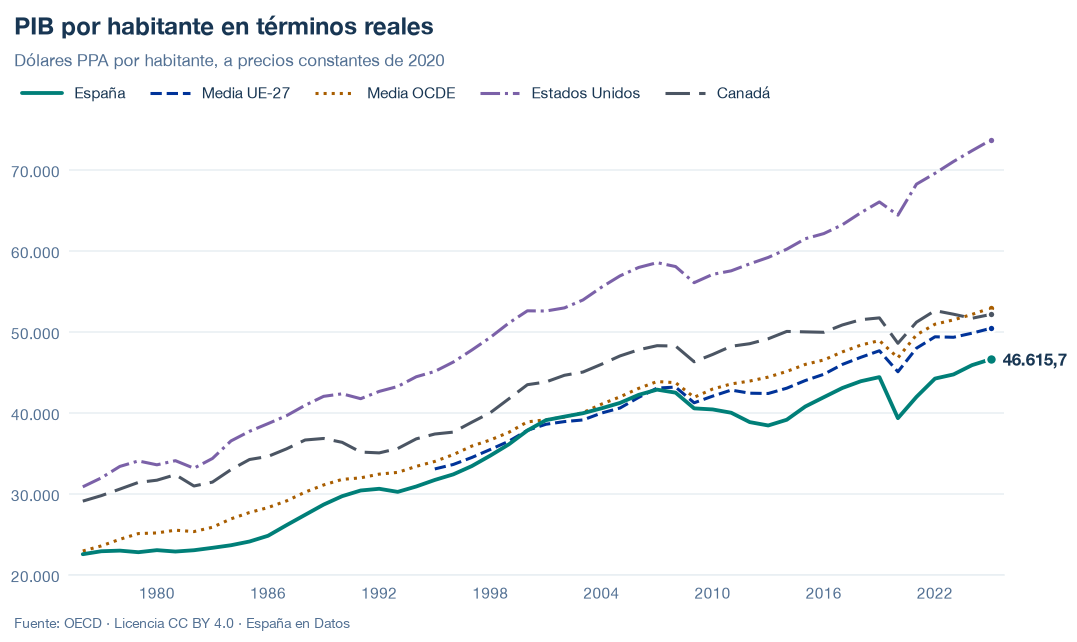

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/pib-per-capita.json y data/pib-per-capita.csv


## 6. Fuentes, notas y licencia

**Fuentes:** OCDE, National Accounts at a Glance, `OECD.SDD.NAD,DSD_NAAG@DF_NAAG_I,1.0` (`B1GQ_R_POP`, `USD_PPP_PS`). La fecha de consulta de cada serie está en `fuentes` del JSON.

**Notas:** en `NOTAS` (año base, agregado de la Unión Europea y observaciones estimadas); `writer.py` añade el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.